<a href="https://colab.research.google.com/github/olonok69/SSL_pathology_demo/blob/main/notebooks/06_anomaly_detection_on_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 · Anomaly detection on embeddings

**Goal.** Fit a head on normal tiles only, then ask whether a new backbone helps when that head stays the same.

**What you will see.** Three heads (kNN distance, shrinkage Mahalanobis, Isolation Forest) on Task A, on the same NCT-CRC tiles as notebook 04 when they are cached (PathMNIST otherwise): non-tumour tissue is normal, colorectal adenocarcinoma is the anomaly, background is held out and reported as a flag rate. Task B (normal lymph node vs metastasis) runs only if notebook 03 cached PatchCamelyon features. Then the false-positive gallery: normal tiles the head ranked as most abnormal.

**Runtime.** About 15 minutes on cached features.

**Talking point.** Slides 22–27. The decision rule is fixed in this cell, before any score is computed.

## Decision rule (fixed before the numbers)

A backbone is clearly better if its AUROC 95% CI does not overlap the next-best backbone's CI on **both** Task A and Task B, for the kNN-distance head. Same tiles, same head, same seeds.

If Task B is not in the cache, the rule cannot name a cross-task winner. Overlapping intervals mean "not clearly better", even when the point estimate is higher. The threshold for sensitivity and false positives is the 99th percentile of scores on held-out normal tiles, not a threshold tuned on tumours.

## Why the kNN head centres the features

An earlier run of this notebook scored cosine distance on the raw features, and the untrained ResNet-50 came first on both tasks. The cause was the geometry, not the backbones. Pretrained features share a large common direction, so every tile has a cosine of about 0.82 to the normal centroid, and raw cosine distances are compressed into a narrow band. The untrained network is the extreme case: every tile points along the centroid (cosine 1.000), and the tiny differences left are mostly stain intensity, which happens to separate dense tumour tiles. The head now subtracts the mean of the normal fit features before the cosine. The cell below shows both versions side by side, so the effect is visible rather than asserted.

In [1]:
import os
import subprocess
from pathlib import Path
repo = Path("/content/SSL_pathology_demo")
if not (repo / "pyproject.toml").exists():
    subprocess.check_call([
        "git", "clone", "--depth", "1",
        "https://github.com/olonok69/SSL_pathology_demo.git",
        str(repo),
    ])
os.chdir(repo)

In [2]:
MODE = "fast"  # "fast" or "full"

import os
import sys
from pathlib import Path

def _find_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "ssl_demo").is_dir():
            return candidate
    raise FileNotFoundError(
        "Launch this notebook from the ssl-pathology-demo repository "
        "(the folder that contains pyproject.toml)."
    )

REPO = _find_repo()
os.chdir(REPO)
src = str(REPO / "src")
if src not in sys.path:
    sys.path.insert(0, src)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    import subprocess
    # pyproject.toml does not pin torch, so a Colab CUDA wheel stays installed.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)])

from ssl_demo.config import SEED, cache_root

CACHE = cache_root()
print(f"MODE={MODE}  SEED={SEED}")
print(f"cache: {CACHE}")


Mounted at /content/drive
MODE=fast  SEED=42
cache: /content/drive/MyDrive/ssl-demo


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from ssl_demo.anomaly import (
    DECISION_RULE,
    KNNDistanceHead,
    anomaly_test_set,
    centroid_cosine,
    decide_backbone,
    highest_scoring,
    normal_pool,
    run_anomaly_task,
    split_fit_holdout,
)
from ssl_demo.backbones import PHASE1_BACKBONES
from ssl_demo.config import ANOMALY_CSV, save_results_csv
from ssl_demo.data import (
    BACKGROUND_ID,
    CLASS_NAMES,
    NORMAL_IDS,
    PCAM_NORMAL_ID,
    PCAM_TUMOUR_ID,
    TUMOUR_ID,
    feature_dir,
    prepare_nct,
    prepare_pathmnist,
)
from ssl_demo.extract import is_cached, load_cached

print(DECISION_RULE)
print()
print("Task A normal classes:", [CLASS_NAMES[i] for i in NORMAL_IDS])
print("Task A anomaly:", CLASS_NAMES[TUMOUR_ID])
print("Held out of the fit:", CLASS_NAMES[BACKGROUND_ID])

In [ ]:
def _require(dataset: str) -> None:
    for name in PHASE1_BACKBONES:
        for split in ("train", "test"):
            if not is_cached(feature_dir(CACHE, dataset, split, MODE), name):
                raise FileNotFoundError(
                    f"Missing {dataset} {split} features for {name}. Run notebook 03 first."
                )

# Task A uses the same tiles as notebook 04: NCT-CRC when cached, PathMNIST otherwise.
nct_ready = all(
    is_cached(feature_dir(CACHE, "nct", split, MODE), name)
    for name in PHASE1_BACKBONES
    for split in ("train", "test")
)
DATASET_A = "nct" if nct_ready else "pathmnist"
_require(DATASET_A)
print("Task A dataset:", DATASET_A)

# Images are only needed for the false-positive gallery.
test_images = None
if DATASET_A == "pathmnist":
    test_images = prepare_pathmnist(mode=MODE, cache=CACHE, seed=SEED, size=224, download=True)["test"]
else:
    NCT_ROOT = os.environ.get("NCT_ROOT", "/content/nct")
    try:
        test_images = prepare_nct(NCT_ROOT, mode=MODE, cache=CACHE, seed=SEED)["test"]
    except FileNotFoundError as exc:
        print("Gallery will be skipped:", exc)

frames = []
runs = {}
features_a = {}
for name in PHASE1_BACKBONES:
    train = load_cached(feature_dir(CACHE, DATASET_A, "train", MODE), name)
    test = load_cached(feature_dir(CACHE, DATASET_A, "test", MODE), name)
    pool, _positions = normal_pool(train.features, train.labels, NORMAL_IDS)
    background = train.features[train.labels == BACKGROUND_ID]
    eval_x, eval_y, eval_pos = anomaly_test_set(
        test.features, test.labels, NORMAL_IDS, (TUMOUR_ID,)
    )
    features_a[name] = (pool, eval_x, eval_y)
    run = run_anomaly_task(
        pool,
        eval_x,
        eval_y,
        backbone=name,
        task="task_a",
        dataset=DATASET_A,
        n_boot=1000,
        background_features=background,
        test_positions=test.index[eval_pos],
    )
    frames.append(run.table)
    runs[name] = run
    print(f"{name}: fit pool {len(pool)}, test rows {len(eval_y)}, tumour {int(eval_y.sum())}")

## Raw versus centred cosine

Same features, same k, same fit tiles. The only change is whether the normal mean is subtracted before the cosine. A centroid cosine near 1 means the raw distances carry very little information about tissue.

In [ ]:
# Same fit tiles as run_anomaly_task: the held-out 20% is kept for the threshold.
rows = []
for name, (pool, eval_x, eval_y) in features_a.items():
    fit_positions, _hold = split_fit_holdout(len(pool), 0.2, SEED)
    fit = pool[fit_positions]
    raw = KNNDistanceHead(center=False).fit(fit).score(eval_x)
    centred = KNNDistanceHead(center=True).fit(fit).score(eval_x)
    rows.append({
        "backbone": name,
        "centroid_cosine": round(centroid_cosine(fit), 3),
        "auroc_raw_cosine": round(roc_auc_score(eval_y, raw), 3),
        "auroc_centred_cosine": round(roc_auc_score(eval_y, centred), 3),
    })
centring = pd.DataFrame(rows)
centring.insert(0, "dataset", DATASET_A)
save_results_csv(centring, "anomaly_centring.csv", CACHE)
centring.set_index("backbone")

In [5]:
pcam_ready = all(
    is_cached(feature_dir(CACHE, "pcam", split, MODE), name)
    for name in PHASE1_BACKBONES
    for split in ("train", "test")
)
if pcam_ready:
    for name in PHASE1_BACKBONES:
        train = load_cached(feature_dir(CACHE, "pcam", "train", MODE), name)
        test = load_cached(feature_dir(CACHE, "pcam", "test", MODE), name)
        pool, _positions = normal_pool(train.features, train.labels, (PCAM_NORMAL_ID,))
        eval_x, eval_y, eval_pos = anomaly_test_set(
            test.features, test.labels, (PCAM_NORMAL_ID,), (PCAM_TUMOUR_ID,)
        )
        run = run_anomaly_task(
            pool,
            eval_x,
            eval_y,
            backbone=name,
            task="task_b",
            dataset="pcam",
            n_boot=1000,
            test_positions=test.index[eval_pos],
        )
        frames.append(run.table)
        print(f"task B {name}: fit pool {len(pool)}, test rows {len(eval_y)}")
else:
    print(
        "Task B skipped: no PatchCamelyon feature cache. "
        "The two-task rule cannot declare a winner from Task A alone."
    )

results = pd.concat(frames, ignore_index=True)
paths = save_results_csv(results, ANOMALY_CSV, CACHE)
print("wrote", paths[0])


task B random_resnet50: fit pool 2500, test rows 2000
task B sup_resnet50_in1k: fit pool 2500, test rows 2000
task B dinov2_vits14: fit pool 2500, test rows 2000
wrote /content/drive/MyDrive/ssl-demo/results/anomaly.csv


In [6]:
auroc = results[(results["metric"] == "auroc") & (~results["task"].str.endswith("background"))]
pivot = auroc.pivot_table(index="backbone", columns=["task", "head"], values="value")
print(pivot.to_string())

decision = decide_backbone(results)
print(decision.reason)
print("winner:", decision.winner)


task                        task_a                                    task_b                         
head              isolation_forest knn_distance mahalanobis isolation_forest knn_distance mahalanobis
backbone                                                                                             
dinov2_vits14             0.439867     0.674869    0.601605         0.476755     0.512384    0.507649
random_resnet50           0.861544     0.898002    0.887705         0.649658     0.716268    0.690864
sup_resnet50_in1k         0.407491     0.687793    0.617945         0.479818     0.572409    0.551605
random_resnet50 is clearly better on both tasks. task_a: random_resnet50 AUROC 0.898 [0.881, 0.914] is clear of sup_resnet50_in1k [0.660, 0.713]. task_b: random_resnet50 AUROC 0.716 [0.694, 0.737] is clear of sup_resnet50_in1k [0.548, 0.598].
winner: random_resnet50


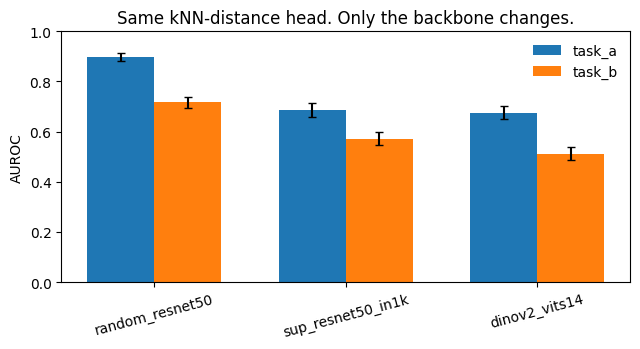

In [7]:
# Backbone-swap view: kNN-distance AUROC, the head named in the rule.
block = auroc[auroc["head"] == "knn_distance"]
tasks = list(block["task"].unique())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(PHASE1_BACKBONES))
width = 0.35 if len(tasks) > 1 else 0.5
for i, task in enumerate(tasks):
    chunk = block[block["task"] == task].set_index("backbone").loc[list(PHASE1_BACKBONES)]
    offset = (i - (len(tasks) - 1) / 2) * width
    ax.bar(x + offset, chunk["value"], width=width, label=task)
    low = np.clip(chunk["value"] - chunk["ci_low"], 0, None)
    high = np.clip(chunk["ci_high"] - chunk["value"], 0, None)
    ax.errorbar(
        x + offset,
        chunk["value"],
        yerr=[low, high],
        fmt="none",
        ecolor="black",
        capsize=3,
    )
ax.set_xticks(x)
ax.set_xticklabels(PHASE1_BACKBONES, rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel("AUROC")
ax.set_title("Same kNN-distance head. Only the backbone changes.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## False-positive gallery

These are test tiles from **non-tumour** classes that the kNN-distance head scored as most abnormal. Debris, folds and edge tiles often land here. That is normal variation and artefact, and it is why a high score is not yet a tumour call.


In [ ]:
if test_images is None:
    print("No tile images for this dataset in this session, so the gallery is skipped.")
else:
    fig, axes = plt.subplots(len(PHASE1_BACKBONES), 6, figsize=(12, 2.4 * len(PHASE1_BACKBONES)))
    for row, name in enumerate(PHASE1_BACKBONES):
        run = runs[name]
        normal = run.test_y == 0
        _local, scores = highest_scoring(
            np.flatnonzero(normal),
            run.scores["knn_distance"][normal],
            k=6,
        )
        for col, position in enumerate(_local):
            source_index = int(run.test_positions[int(position)])
            axes[row, col].imshow(test_images.image(source_index))
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(f"#{col + 1}", fontsize=9)
            if col == 0:
                axes[row, col].set_ylabel(name, fontsize=8)
            axes[row, col].set_xlabel(f"{scores[col]:.2f}", fontsize=8)
    fig.suptitle("Highest-scoring normal test tiles (kNN distance)")
    fig.tight_layout()
    plt.show()

## What we learned

- The three heads see only normal features at fit time. Tumour tiles are used when we score, not when we choose the threshold.
- Swapping the backbone and keeping the head is the whole comparison. The rule above either names a winner on both tasks or it refuses to.
- The head's geometry decides the ranking as much as the backbone does. On raw cosine an untrained network looked best; after centring it falls to chance and the pretrained backbones lead. A random network beating a trained one is a pipeline bug until proven otherwise, and `decide_backbone` now refuses to name a winner in that case.
- The gallery is the artefact story: a high score on debris or a fold is a false positive, and background was kept out of the AUROC for the same reason.

Table: `results/anomaly.csv`.